# Reconhecimento Facial

Este notebook implementa um projeto de reconhecimento facial em Python com o seguinte objetivo:
- usar **4 fotos por pessoa para treinamento**;
- usar uma **5ª foto (não vista no treino) para teste**;
- identificar automaticamente a pessoa mais provável;
- avaliar se o reconhecimento foi bem-sucedido.


## 1. Estratégia do algoritmo

Pipeline utilizado:
1. localizar e recortar a face em cada imagem.
2. converter a face em um vetor numérico com modelo pré-treinado.
3. média dos 4 embeddings de treino.
4. comparar a foto de teste com todos os perfis via similaridade cosseno.
5. se a melhor similaridade for baixa, rotular como **Desconhecido**.


In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from deepface import DeepFace
from sklearn.metrics.pairwise import cosine_similarity


26-10-20 11:10:37 - ⚠️ 
 ⚠️ DEPRECATION WARNING:
 Running 'pip install deepface' alone will no longer be sufficient and will
 NOT install a default backend in an upcoming major release.

 Currently, TensorFlow is included by default, but this behavior will be deprecated.
 Please explicitly specify your preferred backend engine when installing:

   -> pip install deepface[tensorflow]
   -> pip install deepface[pytorch]

 Otherwise, you will encounter 'module not found' errors.




In [2]:
# Configurações principais
DATASET_DIR = Path("dataset_atividade_1")
CONHECIDOS_DIR = DATASET_DIR / "conhecidos"
DESCONHECIDOS_DIR = DATASET_DIR / "desconhecidos"

MODEL_NAME = "Facenet512"
DETECTOR_BACKEND = "retinaface"

print(f"Modelo: {MODEL_NAME}")
print(f"Detector: {DETECTOR_BACKEND}")

Modelo: Facenet512
Detector: retinaface


## 2. Carregamento e validação do dataset

Esperado para cada pessoa em `dataset/conhecidos/<nome>/`:
- `treino/` com, no mínimo, 4 imagens;
- `teste/` com pelo menos 1 imagem.


In [3]:
if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Diretório não encontrado: {DATASET_DIR.resolve()}")

if not CONHECIDOS_DIR.exists():
    raise FileNotFoundError(f"Diretório não encontrado: {CONHECIDOS_DIR.resolve()}")
if not DESCONHECIDOS_DIR.exists():
    raise FileNotFoundError(f"Diretório não encontrado: {DESCONHECIDOS_DIR.resolve()}")

# Função para listar APENAS imagens em uma pasta
def listar_imagens(pasta: Path):
    extensoes = ("*.jpg", "*.jpeg", "*.png")

    arquivos = []
    
    for ext in extensoes:
        arquivos.extend(pasta.glob(ext))
    
    return sorted(arquivos)


dataset = {}

# Montando o dataset de conhecidos
for pessoa_dir in sorted(CONHECIDOS_DIR.iterdir()):
    if not pessoa_dir.is_dir():
        continue

    treino_dir = pessoa_dir / "treino"
    teste_dir = pessoa_dir / "teste"

    imagens_treino = listar_imagens(treino_dir) if treino_dir.exists() else []
    imagens_teste = listar_imagens(teste_dir) if teste_dir.exists() else []

    dataset[pessoa_dir.name] = {
        "treino": imagens_treino,
        "teste": imagens_teste,
    }

print(f"Pessoas encontradas: {len(dataset)}")

for pessoa, dados in dataset.items():
    print(f"- {pessoa}: treino={len(dados['treino'])} | teste={len(dados['teste'])}")

Pessoas encontradas: 6
- Carlos: treino=4 | teste=1
- Gabriela: treino=4 | teste=1
- Gustavo: treino=4 | teste=1
- Tatiana: treino=4 | teste=1
- Tom Holland: treino=4 | teste=1
- Zendaya: treino=4 | teste=1


In [4]:
# Validando o dataset
erros_dataset = []

for pessoa, dados in dataset.items():
    if len(dados["treino"]) < 4:
        erros_dataset.append(f"{pessoa}: menos de 4 imagens de treino")

    if len(dados["teste"]) < 1:
        erros_dataset.append(f"{pessoa}: sem imagem de teste")

if erros_dataset:
    print("Problemas encontrados no dataset:")

    for erro in erros_dataset:
        print(" -", erro)
    raise ValueError("Corrija o dataset antes de continuar.")

print("Dataset validado com sucesso.")

Dataset validado com sucesso.


## 3. Funções para o reconhecimento facial

In [5]:
# Função para detectar rosto em uma imagem e retornar o rosto recortado
def detectar_rosto(caminho_imagem: Path):
    imagem = cv2.imread(str(caminho_imagem))

    if imagem is None:
        raise ValueError(f"Não foi possível carregar a imagem: {caminho_imagem}")

    # Detectando rosto usando DeepFace
    faces = DeepFace.extract_faces(
        img_path=str(caminho_imagem),
        detector_backend=DETECTOR_BACKEND,
        enforce_detection=True,
        align=True,
    )

    if len(faces) != 1:
        raise ValueError(
            f"Esperava 1 rosto em '{caminho_imagem.name}', mas encontrei {len(faces)}."
        )

    area = faces[0]["facial_area"]
    x, y, w, h = area["x"], area["y"], area["w"], area["h"]

    rosto = imagem[y:y+h, x:x+w]

    return {
        "imagem_original": imagem,
        "rosto": rosto,
        "bounding_box": (x, y, w, h),
    }


# Função para desenhar a bounding box em uma imagem
def desenhar_bounding_box(imagem, bounding_box):
    img = imagem.copy()

    # Bounding box é uma tupla (x, y, w, h)
    # utilizada para desenhar um retângulo na imagem
    # mais especificamente na área do rosto detectado
    x, y, w, h = bounding_box

    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 3)

    return img


# Função para visualizar a detecção de rosto em uma imagem
def visualizar_deteccao(resultado, titulo="Detecção facial"):
    # Resultado é um dicionário retornado pela função detectar_rosto
    original = resultado["imagem_original"]

    # Desenhando a bounding box na imagem original
    com_box = desenhar_bounding_box(original, resultado["bounding_box"])

    # Extraindo o rosto recortado
    rosto = resultado["rosto"]

    # Convertendo imagens de BGR para RGB para exibição com Matplotlib
    original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    box_rgb = cv2.cvtColor(com_box, cv2.COLOR_BGR2RGB)
    rosto_rgb = cv2.cvtColor(rosto, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original_rgb)
    plt.title("Imagem original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(box_rgb)
    plt.title("Bounding box")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(rosto_rgb)
    plt.title("Rosto recortado")
    plt.axis("off")

    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

In [6]:
# Função para extrair o embedding de uma imagem
def extrair_embedding(caminho_imagem: Path):
    # Utilizando DeepFace para extrair o embedding da imagem
    # as embeddings são vetores de características que representam o rosto
    representacoes = DeepFace.represent(
        img_path=str(caminho_imagem),
        model_name=MODEL_NAME,
        detector_backend=DETECTOR_BACKEND,
        enforce_detection=True,
        align=True,
    )

    if len(representacoes) != 1:
        raise ValueError(
            f"Esperava 1 rosto em '{caminho_imagem.name}', mas encontrei {len(representacoes)}."
        )

    return np.array(representacoes[0]["embedding"], dtype=np.float32)


# Função para calcular a similaridade entre dois embeddings
def calcular_similaridade(embedding_1, embedding_2):
    return float(cosine_similarity(embedding_1.reshape(1, -1), embedding_2.reshape(1, -1))[0][0])


# Função para reconhecer rosto em uma imagem com base em perfis faciais conhecidos
def reconhecer_rosto(caminho_imagem: Path, perfis_faciais: dict, limiar: float = None):
    # Extraindo o embedding da imagem de teste
    embedding_teste = extrair_embedding(caminho_imagem)

    similaridades = {}

    # Calculando a similaridade entre o embedding de teste e cada perfil facial conhecido
    for pessoa, perfil in perfis_faciais.items():
        similaridades[pessoa] = calcular_similaridade(embedding_teste, perfil)

    # Identificando a pessoa mais próxima com base na similaridade
    # guarda quem venceu a comparação
    pessoa_mais_proxima = max(similaridades, key=similaridades.get)
    # Obtendo a melhor similaridade
    # guarda com qual pontuação essa pessoa venceu.
    melhor_similaridade = similaridades[pessoa_mais_proxima]

    if limiar is None:
        predicao = pessoa_mais_proxima
    else:
        predicao = pessoa_mais_proxima if melhor_similaridade >= limiar else "Desconhecido"

    return {
        "predicao": predicao,
        "pessoa_mais_proxima": pessoa_mais_proxima,
        "similaridade": melhor_similaridade,
        "similaridades": similaridades,
    }

## 4. Exemplo de detecção facial

26-10-20 11:10:58 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: C:\Users\gabis\.deepface\weights\retinaface.h5
100%|██████████| 119M/119M [00:04<00:00, 27.4MB/s] 


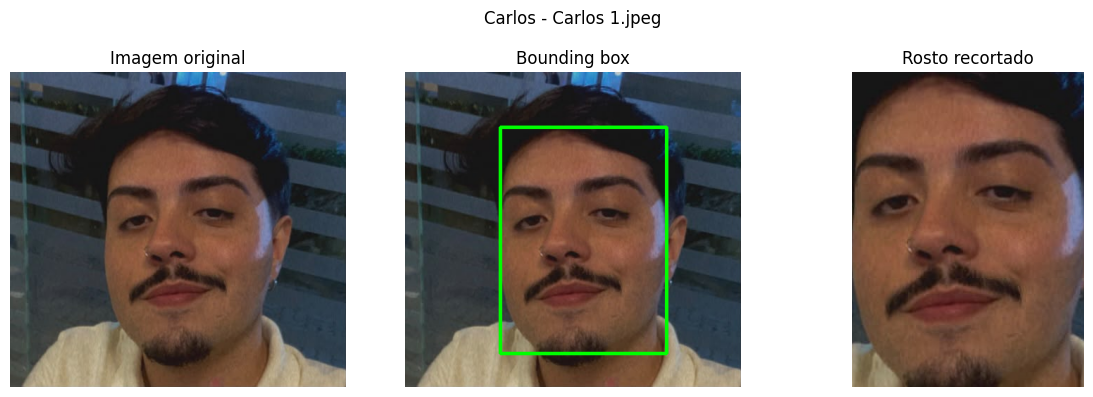

In [7]:
pessoa_exemplo = list(dataset.keys())[0]
imagem_exemplo = dataset[pessoa_exemplo]["treino"][0]

resultado_deteccao = detectar_rosto(imagem_exemplo)
visualizar_deteccao(resultado_deteccao, titulo=f"{pessoa_exemplo} - {imagem_exemplo.name}")

## 5. Treinamento: embeddings e perfil facial médio

Para cada pessoa, geramos embeddings das 4 imagens de treino e calculamos a média.
Esse vetor médio funciona como a referencia da pessoa no banco.

In [8]:
embeddings_treino = {}

# Criando perfis faciais para cada pessoa com base nas imagens de treino
for pessoa, dados in dataset.items():
    embeddings_pessoa = []

    for caminho in dados["treino"][:4]:  # usa as 4 imagens de treinamento
        embeddings_pessoa.append(extrair_embedding(caminho))

    embeddings_treino[pessoa] = embeddings_pessoa

perfis_faciais = {}

# Criando perfis faciais para cada pessoa com base nas embeddings de treino
for pessoa, embeddings in embeddings_treino.items():
    perfis_faciais[pessoa] = np.mean(np.array(embeddings), axis=0)

print("Perfis faciais criados:")

for pessoa, perfil in perfis_faciais.items():
    print(f"- {pessoa}: dimensão {perfil.shape[0]}")

Perfis faciais criados:
- Carlos: dimensão 512
- Gabriela: dimensão 512
- Gustavo: dimensão 512
- Tatiana: dimensão 512
- Tom Holland: dimensão 512
- Zendaya: dimensão 512


## 6. Teste principal: 5ª foto de cada pessoa (sem limiar)

Aqui avaliamos apenas identificação entre cadastrados (quem é o mais parecido).

In [9]:
resultados_conhecidos = []

# Avaliando o desempenho do reconhecimento facial com imagens de teste
for pessoa_real, dados in dataset.items():
    imagem_teste = dados["teste"][0]

    resultado = reconhecer_rosto(imagem_teste, perfis_faciais, limiar=None)

    # Verificando se a predição está correta
    acertou = resultado["predicao"] == pessoa_real

    resultados_conhecidos.append({
        "imagem": imagem_teste.name,
        "pessoa_real": pessoa_real,
        "predicao": resultado["predicao"],
        "similaridade": resultado["similaridade"],
        "acertou": acertou,
    })

df_conhecidos = pd.DataFrame(resultados_conhecidos)
df_conhecidos

,imagem,pessoa_real,predicao,similaridade,acertou
0,Carlos 5.jpeg,Carlos,Carlos,0.839875,True
1,5_gabriela.jpg,Gabriela,Gabriela,0.926186,True
2,5_Gustavo.png,Gustavo,Gustavo,0.855557,True
3,tati 5.png,Tatiana,Tatiana,0.714319,True
4,5_tom.jpg,Tom Holland,Tom Holland,0.658212,True
5,5_zendaya.png,Zendaya,Zendaya,0.902047,True


In [10]:
# Calculando a acurácia entre conhecidos
acuracia_conhecidos = df_conhecidos["acertou"].mean()

print(f"Acurácia entre conhecidos: {acuracia_conhecidos:.2%}")

Acurácia entre conhecidos: 100.00%


## 7. Caso "Desconhecido" e calibração do limiar

Agora incluímos imagens fora da base de pessoas cadastradas para decidir quando rejeitar uma identidade.

In [11]:
resultados_desconhecidos = []

if DESCONHECIDOS_DIR.exists():
    # Avaliando o desempenho do reconhecimento facial com imagens desconhecidas
    for caminho in sorted(DESCONHECIDOS_DIR.iterdir()):
        if not caminho.is_file():
            continue

        # Extraindo o embedding da imagem desconhecida
        embedding = extrair_embedding(caminho)

        # Calculando a similaridade entre o embedding da imagem desconhecida e cada perfil facial conhecido
        similaridades = {
            pessoa: calcular_similaridade(embedding, perfil)
            for pessoa, perfil in perfis_faciais.items()
        }

        pessoa_mais_proxima = max(similaridades, key=similaridades.get)
        melhor_similaridade = similaridades[pessoa_mais_proxima]

        resultados_desconhecidos.append({
            "imagem": caminho.name,
            "pessoa_mais_proxima": pessoa_mais_proxima,
            "similaridade": melhor_similaridade,
        })


df_desconhecidos = pd.DataFrame(resultados_desconhecidos)
df_desconhecidos

,imagem,pessoa_mais_proxima,similaridade
0,5_evelyn.png,Gabriela,0.643853


In [12]:
# Função para calibrar o threshold de reconhecimento facial
# scores_conhecidos: lista de similaridades de imagens conhecidas
# scores_desconhecidos: lista de similaridades de imagens desconhecidas
# inicio: valor inicial do threshold
# fim: valor final do threshold
# passo: incremento do threshold
def calibrar_threshold(scores_conhecidos, scores_desconhecidos, inicio=0.0, fim=1.0, passo=0.001):
    # Gerando uma lista de thresholds a serem testados
    thresholds = np.arange(inicio, fim + passo, passo)

    resultados = []

    # Calculando métricas para cada threshold
    for threshold in thresholds:
        # Calculando a taxa de verdadeiros positivos (TPR)
        tpr = (scores_conhecidos >= threshold).mean() if len(scores_conhecidos) else 0.0
        # e a taxa de verdadeiros negativos (TNR)
        tnr = (scores_desconhecidos < threshold).mean() if len(scores_desconhecidos) else 0.0

        # Calculando a acurácia balanceada
        # que é a média entre a taxa de acertos para conhecidos e a taxa de acertos para desconhecidos
        balanced_accuracy = (tpr + tnr) / 2

        resultados.append({
            "threshold": threshold,
            "taxa_conhecidos_aceitos": tpr,
            "taxa_desconhecidos_rejeitados": tnr,
            "balanced_accuracy": balanced_accuracy,
        })

    return pd.DataFrame(resultados)

In [13]:
# Score conhecidos: similaridades das imagens de teste conhecidas
scores_conhecidos = df_conhecidos["similaridade"].values
# Score desconhecidos: similaridades das imagens de teste desconhecidas
scores_desconhecidos = df_desconhecidos["similaridade"].values if not df_desconhecidos.empty else np.array([])

# Calibrando o threshold de reconhecimento facial
if len(scores_desconhecidos) > 0:
    # Chamando a função de calibração do threshold
    df_thresholds = calibrar_threshold(scores_conhecidos, scores_desconhecidos)

    # Calculando o melhor threshold com base na acurácia balanceada
    melhor_score = df_thresholds["balanced_accuracy"].max()
    # Selecionando o threshold correspondente ao melhor score
    melhores = df_thresholds[df_thresholds["balanced_accuracy"] == melhor_score]
    # Selecionando o limiar de reconhecimento como a mediana dos melhores thresholds encontrados
    LIMIAR_RECONHECIMENTO = float(melhores["threshold"].median())
else:
    LIMIAR_RECONHECIMENTO = 0.69  # fallback quando não há base de desconhecidos

print(f"Limiar utilizado: {LIMIAR_RECONHECIMENTO:.3f}")

Limiar utilizado: 0.651


## 8. Avaliação final (conhecidos + desconhecidos)

In [14]:
resultados_avaliacao = []

# Avaliação com imagens conhecidas
for pessoa_real, dados in dataset.items():
    imagem_teste = dados["teste"][0]
    resultado = reconhecer_rosto(imagem_teste, perfis_faciais, limiar=LIMIAR_RECONHECIMENTO)

    resultados_avaliacao.append({
        "imagem": imagem_teste.name,
        "tipo": "Conhecida",
        "pessoa_real": pessoa_real,
        "predicao": resultado["predicao"],
        "similaridade": resultado["similaridade"],
        "correto": resultado["predicao"] == pessoa_real,
    })

# Avaliação com imagens desconhecidas
if DESCONHECIDOS_DIR.exists():
    for caminho in sorted(DESCONHECIDOS_DIR.iterdir()):
        if not caminho.is_file():
            continue

        resultado = reconhecer_rosto(caminho, perfis_faciais, limiar=LIMIAR_RECONHECIMENTO)

        resultados_avaliacao.append({
            "imagem": caminho.name,
            "tipo": "Desconhecida",
            "pessoa_real": "Desconhecido",
            "predicao": resultado["predicao"],
            "similaridade": resultado["similaridade"],
            "correto": resultado["predicao"] == "Desconhecido",
        })


df_avaliacao = pd.DataFrame(resultados_avaliacao)
df_avaliacao

,imagem,tipo,pessoa_real,predicao,similaridade,correto
0,Carlos 5.jpeg,Conhecida,Carlos,Carlos,0.839875,True
1,5_gabriela.jpg,Conhecida,Gabriela,Gabriela,0.926186,True
2,5_Gustavo.png,Conhecida,Gustavo,Gustavo,0.855557,True
3,tati 5.png,Conhecida,Tatiana,Tatiana,0.714319,True
4,5_tom.jpg,Conhecida,Tom Holland,Tom Holland,0.658212,True
5,5_zendaya.png,Conhecida,Zendaya,Zendaya,0.902047,True
6,5_evelyn.png,Desconhecida,Desconhecido,Desconhecido,0.643853,True


In [15]:
# Acurácia geral: proporção de acertos em relação ao total de amostras avaliadas
acuracia_geral = df_avaliacao["correto"].mean() if len(df_avaliacao) else 0.0

# Separando os resultados de avaliação entre conhecidos e desconhecidos
df_av_conhecidos = df_avaliacao[df_avaliacao["tipo"] == "Conhecida"]
df_av_desconhecidos = df_avaliacao[df_avaliacao["tipo"] == "Desconhecida"]

# Taxa de reconhecimento: proporção de acertos entre conhecidos
taxa_reconhecimento = df_av_conhecidos["correto"].mean() if len(df_av_conhecidos) else 0.0
# Taxa de rejeição: proporção de acertos entre desconhecidos
taxa_rejeicao = df_av_desconhecidos["correto"].mean() if len(df_av_desconhecidos) else 0.0

# Falsos positivos: imagens desconhecidas que foram classificadas como conhecidas
falsos_positivos = df_avaliacao[
    (df_avaliacao["tipo"] == "Desconhecida") & (df_avaliacao["predicao"] != "Desconhecido")
]

# Falsos negativos: imagens conhecidas que foram classificadas como desconhecidas
falsos_negativos = df_avaliacao[
    (df_avaliacao["tipo"] == "Conhecida") & (df_avaliacao["predicao"] == "Desconhecido")
]

# Identificações incorretas: imagens conhecidas que foram classificadas como outra pessoa conhecida
identificacoes_incorretas = df_avaliacao[
    (df_avaliacao["tipo"] == "Conhecida")
    & (df_avaliacao["predicao"] != "Desconhecido")
    & (df_avaliacao["predicao"] != df_avaliacao["pessoa_real"])
]

print("=" * 50)
print("RESUMO FINAL DA AVALIAÇÃO")
print("=" * 50)
print(f"Total de amostras avaliadas: {len(df_avaliacao)}")
print(f"Acurácia geral: {acuracia_geral:.2%}")
print(f"Taxa de reconhecimento (conhecidos): {taxa_reconhecimento:.2%}")
print(f"Taxa de rejeição (desconhecidos): {taxa_rejeicao:.2%}")
print(f"Falsos positivos: {len(falsos_positivos)}")
print(f"Falsos negativos: {len(falsos_negativos)}")
print(f"Identificações incorretas: {len(identificacoes_incorretas)}")
print(f"Limiar utilizado: {LIMIAR_RECONHECIMENTO:.3f}")


RESUMO FINAL DA AVALIAÇÃO
Total de amostras avaliadas: 7
Acurácia geral: 100.00%
Taxa de reconhecimento (conhecidos): 100.00%
Taxa de rejeição (desconhecidos): 100.00%
Falsos positivos: 0
Falsos negativos: 0
Identificações incorretas: 0
Limiar utilizado: 0.651


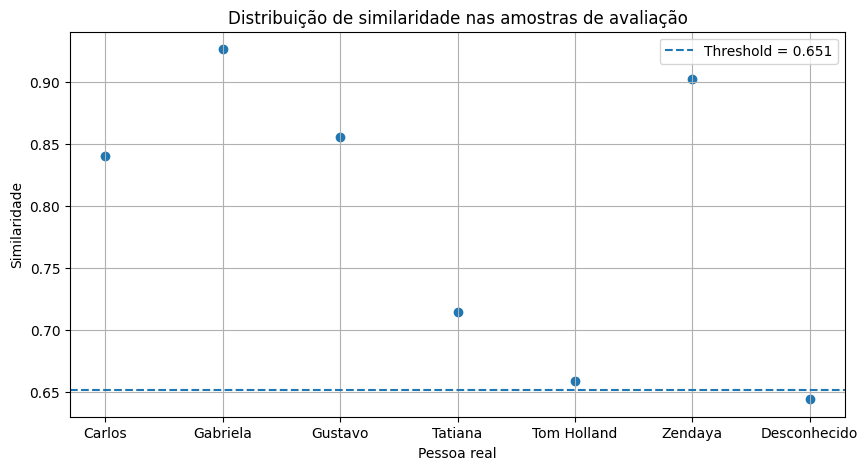

In [16]:
# Visualização da distribuição de similaridade nas amostras de avaliação
plt.figure(figsize=(10, 5))

plt.scatter(df_avaliacao["pessoa_real"], df_avaliacao["similaridade"])
plt.axhline(
    y=LIMIAR_RECONHECIMENTO,
    linestyle="--",
    label=f"Threshold = {LIMIAR_RECONHECIMENTO:.3f}",
)

plt.xlabel("Pessoa real")
plt.ylabel("Similaridade")
plt.title("Distribuição de similaridade nas amostras de avaliação")
plt.legend()
plt.grid(True)
plt.show()


## 9. Conclusão

Com este protótipo, foi possível demonstrar o fluxo completo de reconhecimento facial:
- treino com 4 imagens por pessoa;
- teste com imagem não vista;
- decisão por similaridade e limiar;
- avaliação quantitativa dos resultados.

### Limitações
- Base pequena de pessoas/imagens;
- sensibilidade a iluminação, pose e qualidade das fotos;
- limiar depende do conjunto de calibração e deve ser revisado ao expandir a base.